# 02 · Demand patterns: trend, seasonality, COVID

**Question:** what structure does a forecaster have to capture, and where does it break?

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.seasonal import STL

from nhsae import viz
from nhsae.config import PANEL

viz.set_style()
panel = pd.read_csv(PANEL, parse_dates=["month"])
eng = panel.groupby("month")[["attendances", "emergency_admissions"]].sum().asfreq("MS")
daily = eng.div(eng.index.days_in_month, axis=0)

## 1. England, eight years
Monthly totals mix real change with calendar noise (February has 28 days), so everything below uses
**attendances per day**.

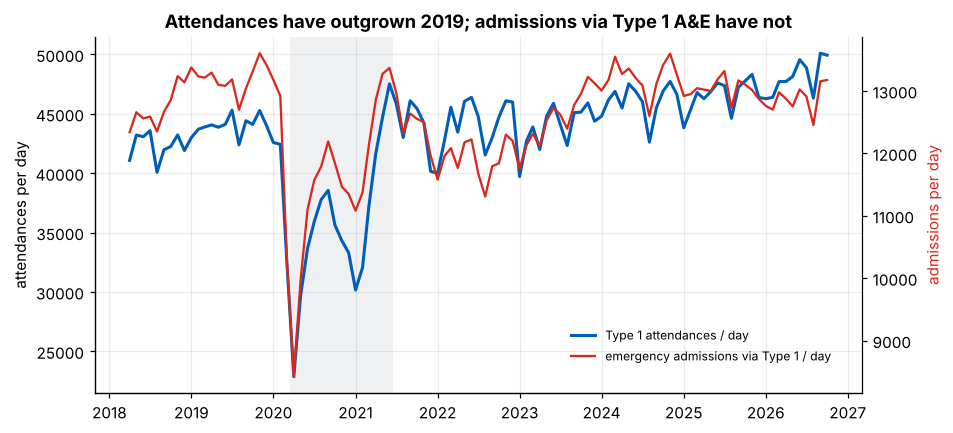

In [2]:
fig, ax = plt.subplots()
viz.covid_band(ax)
ax.plot(daily.index, daily.attendances, color=viz.NHS_BLUE, lw=2, label="Type 1 attendances / day")
ax2 = ax.twinx()
ax2.plot(daily.index, daily.emergency_admissions, color=viz.NHS_RED, lw=1.5, label="emergency admissions via Type 1 / day")
ax2.spines["right"].set_visible(True)
ax2.grid(False)
ax.set_title("Attendances have outgrown 2019; admissions via Type 1 A&E have not")
ax.set_ylabel("attendances per day")
ax2.set_ylabel("admissions per day", color=viz.NHS_RED)
fig.legend(loc="lower right", bbox_to_anchor=(0.88, 0.15), fontsize=8)
viz.save(fig, "02_england_trend")

In [3]:
yr = daily.groupby(daily.index.year).mean().round(0).astype(int)
yr["admissions per 100 attendances"] = (100 * yr.emergency_admissions / yr.attendances).round(1)
yr

,attendances,emergency_admissions,admissions per 100 attendances
month,,,
2018,42267,12710,30.1
2019,44019,13213,30.0
2020,34939,11341,32.5
2021,41515,12419,29.9
2022,44198,11909,26.9
2023,43836,12555,28.6
2024,46105,13220,28.7
2025,46542,13027,28.0
2026,48108,12879,26.8


Attendances per day in 2026 are about 9% above 2019, but admissions via Type 1 A&E are about 2.5% *below*,
so the share of attendances admitted has fallen from 30 to about 27 per 100. That is consistent with more
patients being treated without admission (for example through same-day emergency care), though this data alone can't prove it.
A model that extrapolates the 2021–23 admissions recovery will over-forecast admissions. Notebook 05 shows that this is exactly
what happened in the backtest.

## 2. Seasonality
STL decomposition of the log daily rate, post-COVID. Additive on the log scale = multiplicative in levels.

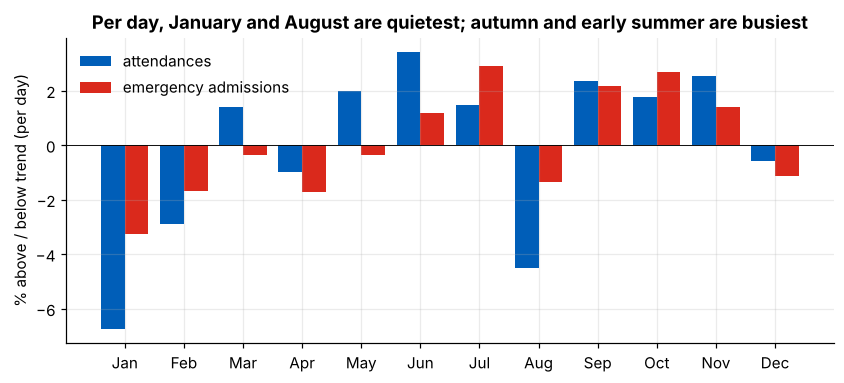

In [4]:
z = np.log(daily.attendances.loc["2021-07":])
stl = STL(z, period=12, robust=True).fit()
season = stl.seasonal.groupby(stl.seasonal.index.month).mean()
zadm = np.log(daily.emergency_admissions.loc["2021-07":])
season_adm = STL(zadm, period=12, robust=True).fit().seasonal
season_adm = season_adm.groupby(season_adm.index.month).mean()
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(1, 13)
ax.bar(x - 0.2, 100 * season.values, width=0.4, color=viz.NHS_BLUE, label="attendances")
ax.bar(x + 0.2, 100 * season_adm.values, width=0.4, color=viz.NHS_RED, label="emergency admissions")
ax.axhline(0, color="black", lw=0.6)
ax.set_xticks(x, ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylabel("% above / below trend (per day)")
ax.set_title("Per day, January and August are quietest; autumn and early summer are busiest")
ax.legend()
viz.save(fig, "02_seasonality")

Per day, A&E demand is **not** highest in winter: January is about 7% below trend for attendances, and
the quietest month for admissions too. Autumn (September to November) and early summer run above trend.
Winter pressure in the NHS comes from what happens *after* A&E (bed occupancy, delayed discharges,
staff sickness), not from a surge at the front door. That is why notebook 06 forecasts 4-hour performance
from the trust's own recent flow, and the demand forecast turns out to be a weak predictor of it.

## 3. Growth is not uniform
Year-on-year growth by region (last 12 months vs the 12 before) shows why top-down splitting with fixed
historical shares will struggle.

In [5]:
reg = panel.groupby(["region_name", "month"]).attendances.sum().unstack(0)
last12 = reg.iloc[-12:].sum()
prev12 = reg.iloc[-24:-12].sum()
growth = (last12 / prev12 - 1).sort_values()
trusts = panel.pivot(index="month", columns="trust_code", values="attendances")
tg = trusts.iloc[-12:].sum() / trusts.iloc[-24:-12].sum() - 1
print(growth.map("{:+.1%}".format).to_string())
print(f"\nTrust-level growth: median {tg.median():+.1%}, 10th–90th percentile {tg.quantile(.1):+.1%} to {tg.quantile(.9):+.1%}")

region_name
East of England             +2.0%
Midlands                    +2.4%
South East                  +2.8%
London                      +3.3%
North East and Yorkshire    +3.7%
North West                  +3.9%
South West                  +4.6%

Trust-level growth: median +3.2%, 10th–90th percentile -2.2% to +8.0%
